# 📘 Chapter 4 — Training Linear Models (My Notes)

*Personal walkthrough of `handson-ml3/04_training_linear_models.ipynb`, with the background I was missing.*

This notebook follows the same order as the official one, but stops to explain the parts that
aren't spelled out in the code — the linear algebra, the notation, and the *why*, not just the *how*.

**Part 1 of several.** We start with everything needed to understand the **Normal Equation**.
Gradient Descent, Polynomial Regression, Regularization, and Logistic/Softmax Regression will
follow in later parts, once this part feels solid.


---
## Part 0 — Essentials before we start

Before touching the book's code, three small things show up immediately and will trip you up
if you don't already know them:

1. How NumPy represents vectors/matrices (**shapes**)
2. What `np.random.seed()` does
3. What `add_dummy_feature()` does, and *why* linear regression needs it

Let's get those out of the way first.


### 0.1 — Vectors as NumPy arrays: why shape `(m, 1)` and not `(m,)`

In plain Python you might just store a list of numbers. In NumPy, **shape matters a lot**.

- A 1-D array `np.array([1, 2, 3])` has shape `(3,)` — it's just a flat list of 3 numbers.
  It is neither a row nor a column.
- A 2-D array with shape `(3, 1)` is an actual **column vector**: 3 rows, 1 column.

Scikit-learn's estimators expect *features* `X` as a 2-D array of shape `(n_samples, n_features)`
— even when there's only one feature, so `X` is `(m, 1)`, never `(m,)`. This matters because
matrix multiplication treats 1-D and 2-D arrays differently, and mixing them up tends to silently
give you a *wrong-shaped* result (via broadcasting) instead of a clean error.


In [1]:
import numpy as np

a_1d = np.array([1, 2, 3])          # shape (3,)   -> flat array
a_2d = np.array([[1], [2], [3]])    # shape (3, 1) -> column vector

print("1-D shape:", a_1d.shape)
print("2-D shape:", a_2d.shape)


1-D shape: (3,)
2-D shape: (3, 1)


### 0.2 — Matrix multiplication: `@` and `.T`

- `.T` **transposes** a matrix (rows become columns).
- `@` is **matrix multiplication** (equivalent to `np.matmul(...)` / `.dot(...)`) — it is
  *not* the same as `*`, which multiplies element-by-element.

For `A @ B` to work, the number of **columns** of `A` must match the number of **rows** of `B`.
The result has the outer shape: `(rows of A, columns of B)`.


In [6]:
A = np.array([[1, 2],
              [3, 4],
              [5, 6]])          # shape (3, 2)

print("A.T shape:      ", A.T.shape)          # (2, 3)
print("(A.T @ A) shape:", (A.T @ A).shape)     # (2, 3) @ (3, 2) -> (2, 2)

# compare with element-wise multiplication (needs matching shapes, does something different!)
print(A * A)
print( A.T * A.T)
print( A @ A.T)
print( A.T @ A)


A.T shape:       (2, 3)
(A.T @ A) shape: (2, 2)
[[ 1  4]
 [ 9 16]
 [25 36]]
[[ 1  9 25]
 [ 4 16 36]]
[[ 5 11 17]
 [11 25 39]
 [17 39 61]]
[[35 44]
 [44 56]]


### 0.3 — `np.random.seed(42)`: making randomness reproducible

NumPy's random number generator is *pseudo-random*: underneath it's actually a deterministic
formula, driven by an internal "state". `np.random.seed(42)` resets that state to a fixed
starting point, so every subsequent call to `np.random.rand()`, `np.random.randn()`, etc.
produces the **exact same sequence** of "random" numbers every time you run the script.

Why `42`? It's simply a fixed number the author picked (a nod to *The Hitchhiker's Guide to the
Galaxy*) — any fixed seed works equally well. What matters isn't the value, it's that it's
**fixed**, so your results are reproducible and comparable run to run (and so your output matches
the book's, when you're following along).


In [9]:
np.random.seed(42)
print(np.random.rand(3))   # always the same 3 numbers, run after run

np.random.seed(42)
print(np.random.rand(3))   # identical to the line above, because we reset the seed

print(np.random.rand(3))   # different! we did NOT reseed, so the generator just moved on


[0.37454012 0.95071431 0.73199394]
[0.37454012 0.95071431 0.73199394]
[0.59865848 0.15601864 0.15599452]


### 0.4 — The bias trick: `add_dummy_feature()`

Our linear regression model looks like:

$$\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n$$

$\theta_0$ is the **bias** (a.k.a. intercept) — it has no matching input feature to multiply.
To write the *whole* right-hand side as a single dot product $\boldsymbol\theta^\top \mathbf{x}$,
we invent a feature $x_0$ that is **always 1**:

$$\hat{y} = \theta_0 \cdot 1 + \theta_1 x_1 + \dots + \theta_n x_n = \boldsymbol\theta^\top \mathbf{x}, \qquad \mathbf{x} = [1, x_1, \dots, x_n]$$

`add_dummy_feature(X)` does exactly this: it prepends a column of 1s to `X`. It is equivalent to
`np.c_[np.ones((m, 1)), X]`.

Once every instance has that leading 1, "learn $\theta_0$" becomes just another weight to learn,
and the whole model collapses into **one matrix multiplication**, `X_b @ theta`, instead of a
bias term that needs to be handled separately.


In [10]:
from sklearn.preprocessing import add_dummy_feature

X_demo = np.array([[1.5], [2.0], [0.3]])
print(add_dummy_feature(X_demo))

# exactly equivalent to doing it by hand:
print(np.c_[np.ones((len(X_demo), 1)), X_demo])


[[1.  1.5]
 [1.  2. ]
 [1.  0.3]]
[[1.  1.5]
 [1.  2. ]
 [1.  0.3]]


---
## Part 1 — The Normal Equation

Now for the actual chapter content. We'll generate a small synthetic dataset with a **known**
underlying relationship, then find the line that best fits it two ways: first by directly
solving the math (the Normal Equation), then by checking that against scikit-learn.


### 1.1 — Generate the data

We generate data from a known "true" relationship, $y = 4 + 3x_1 + \text{noise}$, so we can
later check whether our fitted model recovers something close to $\theta_0=4, \theta_1=3$.

In real projects you never know the ground truth — the whole point of "training" is to
*estimate* $\theta$ from noisy observations. Using synthetic data with a known answer here just
lets us sanity-check that the math is actually working.


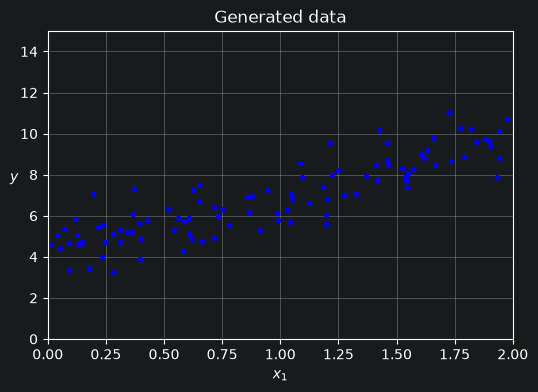

In [11]:
import matplotlib.pyplot as plt

np.random.seed(42)
m = 100                                  # number of training instances
X = 2 * np.random.rand(m, 1)             # random x values in [0, 2), shape (100, 1)
y = 4 + 3 * X + np.random.randn(m, 1)    # true line y = 4 + 3x, plus Gaussian noise

plt.figure(figsize=(6, 4))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.grid()
plt.title("Generated data")
plt.show()


### 1.2 — The cost function: what "best fit" even means

We measure how wrong a given $\theta$ is with the **Mean Squared Error**:

$$J(\boldsymbol\theta) = \text{MSE}(\boldsymbol\theta) = \frac{1}{m}\sum_{i=1}^{m}\left(\boldsymbol\theta^\top \mathbf{x}^{(i)} - y^{(i)}\right)^2 = \frac{1}{m}\lVert \mathbf{X}\boldsymbol\theta - \mathbf{y} \rVert^2$$

"Best fit" = the $\boldsymbol\theta$ that **minimizes** $J(\boldsymbol\theta)$.

Because $J$ is a sum of squares of a *linear* function of $\boldsymbol\theta$, it's a **convex,
bowl-shaped function** of $\boldsymbol\theta$ — there's exactly one minimum, no local minima to
get stuck in. That's precisely what lets us solve for it *directly*, in one shot, instead of
needing an iterative search (that's what Gradient Descent is for — more on that in Part 2).


### 1.3 — Deriving the Normal Equation

To find the minimum of a smooth, convex bowl, we take its **gradient** with respect to
$\boldsymbol\theta$ and set it to zero (the bottom of a bowl is exactly where the slope is flat
in every direction):

$$\nabla_{\boldsymbol\theta}\, J(\boldsymbol\theta) = \frac{2}{m}\mathbf{X}^\top(\mathbf{X}\boldsymbol\theta - \mathbf{y}) = \mathbf{0}$$

Multiplying both sides by $m/2$ and expanding:

$$\mathbf{X}^\top \mathbf{X}\boldsymbol\theta = \mathbf{X}^\top \mathbf{y}$$

If $\mathbf{X}^\top \mathbf{X}$ is invertible, we can solve directly for $\boldsymbol\theta$:

$$\boxed{\hat{\boldsymbol\theta} = (\mathbf{X}^\top \mathbf{X})^{-1}\mathbf{X}^\top \mathbf{y}}$$

This is the **Normal Equation**. No iteration, no learning rate to tune — a single formula gives
the *exact* optimal $\boldsymbol\theta$ for this particular cost function.

One caveat: $\mathbf{X}^\top \mathbf{X}$ has to actually be invertible. That fails if you have
redundant/duplicated features (perfect collinearity) or more features than instances. That's
exactly why, later in this section, the book also shows a more robust alternative
(pseudoinverse via SVD) — we'll get there.


### 1.4 — Connecting it back to `add_dummy_feature`

Our model is $\hat{y} = \theta_0 + \theta_1 x_1$ — 2 parameters. To use the matrix formula
above, every instance needs to look like $\mathbf{x}^{(i)} = [1, x_1^{(i)}]$, so that
$\boldsymbol\theta^\top \mathbf{x}^{(i)} = \theta_0 + \theta_1 x_1^{(i)}$ — exactly what
`add_dummy_feature` gave us in Part 0.


In [12]:
from sklearn.preprocessing import add_dummy_feature

X_b = add_dummy_feature(X)   # add x0 = 1 to each instance -> shape (100, 2)
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
theta_best


array([[4.21509616],
       [2.77011339]])

Here's how each piece of the formula maps to the code:

| Math | Code |
|---|---|
| $\mathbf{X}$ (with the bias column) | `X_b` |
| $\mathbf{X}^\top$ | `X_b.T` |
| $\mathbf{X}^\top \mathbf{X}$ | `X_b.T @ X_b` |
| $(\cdot)^{-1}$ | `np.linalg.inv(...)` |
| $\mathbf{X}^\top \mathbf{y}$ | `X_b.T @ y` |
| $\hat{\boldsymbol\theta}$ | `theta_best` |

You should get `theta_best ≈ [4.215, 2.77]` — close to the true `[4, 3]` we used to generate the
data, but not exact, because of the random noise we added. That gap is expected and unavoidable;
it would shrink if we generated more data points (larger `m`).


### 1.5 — Making predictions

Since predicting is just $\hat y = \boldsymbol\theta^\top \mathbf x$, any **new** input also
needs the bias column added before you can multiply it by `theta_best` — it's easy to forget this
and get a shape-mismatch error.


In [13]:
X_new = np.array([[0], [2]])            # two x values we want predictions for
X_new_b = add_dummy_feature(X_new)      # don't forget the bias column here too!
y_predict = X_new_b @ theta_best
y_predict


array([[4.21509616],
       [9.75532293]])

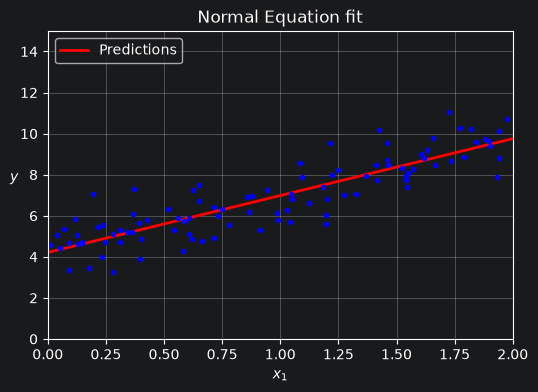

In [14]:
plt.figure(figsize=(6, 4))
plt.plot(X_new, y_predict, "r-", linewidth=2, label="Predictions")
plt.plot(X, y, "b.")
plt.xlabel("$x_1$")
plt.ylabel("$y$", rotation=0)
plt.axis([0, 2, 0, 15])
plt.legend(loc="upper left")
plt.grid()
plt.title("Normal Equation fit")
plt.show()


### 1.6 — Verify with scikit-learn

If our understanding is right, `LinearRegression` should land on the same numbers. Note that
`LinearRegression` handles the intercept **internally** (`fit_intercept=True` by default) — you
pass it the raw `X`, *without* calling `add_dummy_feature` yourself.


In [15]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)                 # raw X here — no add_dummy_feature needed, sklearn does it internally
print(lin_reg.intercept_, lin_reg.coef_)
print(lin_reg.predict(X_new))


[4.21509616] [[2.77011339]]
[[4.21509616]
 [9.75532293]]


### 1.7 — Under the hood: why scikit-learn doesn't literally invert $\mathbf X^\top \mathbf X$

`np.linalg.inv` can be numerically unstable, or fail outright, when $\mathbf X^\top \mathbf X$
is singular or nearly singular (e.g. redundant features, or highly correlated ones). In
practice, `LinearRegression` instead computes the **pseudoinverse** of $\mathbf X$ via
**Singular Value Decomposition (SVD)** — a matrix operation that generalizes "inverse" to
matrices that aren't square or aren't invertible, and that's much more numerically stable. It
gives the identical answer whenever the plain inverse *does* exist, but keeps working even when
it doesn't.


In [16]:
# same result, via a least-squares solve (closer to what LinearRegression does internally)
theta_best_svd, residuals, rank, s = np.linalg.lstsq(X_b, y, rcond=1e-6)
theta_best_svd


array([[4.21509616],
       [2.77011339]])

In [17]:
# or directly via the (Moore-Penrose) pseudoinverse of X_b
np.linalg.pinv(X_b) @ y


array([[4.21509616],
       [2.77011339]])

## ✏️ Check your understanding

Try to answer these without scrolling back up.

1. Why is `X` shaped `(100, 1)` instead of `(100,)`?
2. What would go wrong with `theta_best` if you forgot to call `add_dummy_feature` before
   computing it?
3. Why does the Normal Equation give the *exact* optimal $\theta$ in one step, while Gradient
   Descent (coming up in Part 2) needs many iterations to get there?


**Answers**

1. Scikit-learn (and the matrix math we're using) expects 2-D arrays of shape
   `(n_samples, n_features)`. A 1-D `(100,)` array isn't compatible with matrix multiplication
   the way we're using it here — you'd get shape errors or silently-wrong broadcasting.
2. `X_b` would only have 1 column (just $x_1$), so `theta_best` would only have 1 entry — you'd
   be forcing $\theta_0 = 0$, i.e. fitting a line through the origin. That fits this dataset
   poorly, since the true intercept is 4, not 0.
3. Because $\text{MSE}(\boldsymbol\theta)$ is a convex quadratic function of $\boldsymbol\theta$
   — one smooth bowl with a single minimum — so setting its gradient to zero can be solved
   algebraically, in closed form. Gradient Descent doesn't rely on a closed-form solution
   existing; it works for cost functions where no such neat formula is available, or where
   computing the formula directly (e.g. inverting a huge $n \times n$ matrix when you have
   thousands of features) would be too slow.


---
### Up next

Part 2 will cover **Gradient Descent** — Batch, Stochastic, and Mini-batch — the iterative
alternative to the Normal Equation, and why it's the one that scales to large datasets and to
models that don't have a closed-form solution at all (like Logistic Regression, later in this
chapter).
